# Лабораторная работа 3. Метрические методы классификации


## 1. Загрузка датасета

In [ ]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATASET_FILE_PATH = 'resources/ready_cleaned.csv'
FEATURES = ['Customer_Age', 'Quantity', 'Unit_Price']
TARGET = 'Product_Category'

data = pd.read_csv(DATASET_FILE_PATH)
X = data[FEATURES]
y = data[TARGET]

print("Размер выборки:", X.shape)
print("Пропусков в признаках:", X.isna().sum().sum())
print()
print(y.value_counts(normalize=True).round(3).to_string())

Размер выборки: (2567, 3)
Пропусков в признаках: 0

Product_Category
electronics        0.400
office supplies    0.322
appliances         0.147
furniture          0.131


**Характеристика:**

- 2567 объектов, 3 числовых признака без пропусков
- Классы несбалансированы: electronics – 40%, office supplies – 32.2%, appliances – 14.7%, furniture – 13.1%. Модель, всегда отвечающая «electronics», уже получит accuracy 0.40, поэтому качество нужно сравнивать с этим уровнем, а не с нулём.

## 2. Визуальный анализ

Попарное распределение признаков с раскраской по классам показывает, разделимы ли классы в выбранном признаковом пространстве.

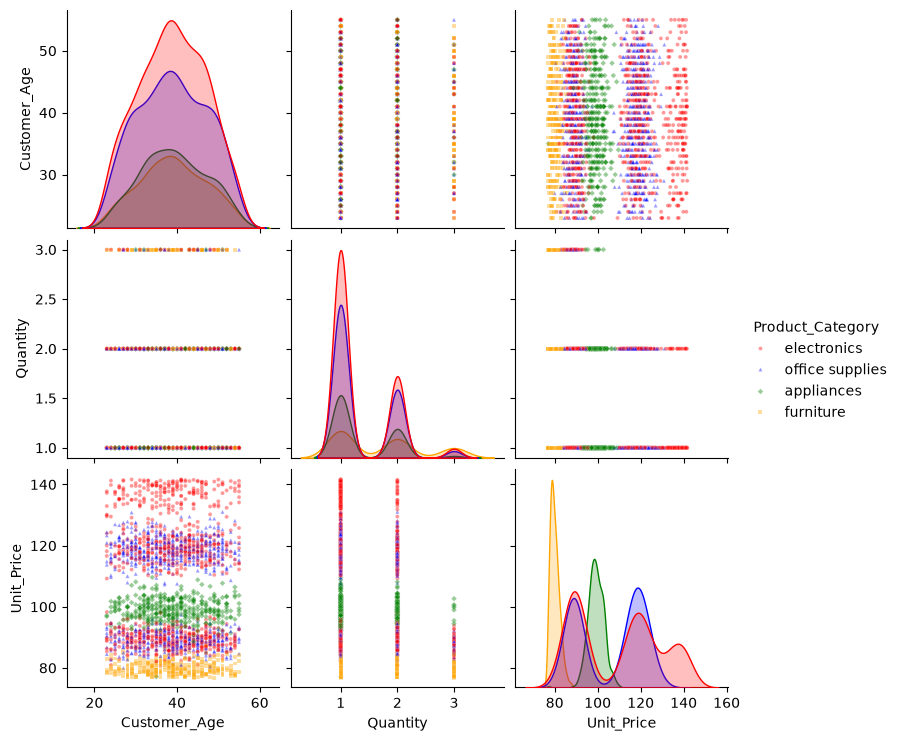

In [ ]:
TYPE_ORDER = ['electronics', 'office supplies', 'appliances', 'furniture']
TYPE_COLORS = ['red', 'blue', 'green', 'orange']
TYPE_MARKERS = ['o', 's', '^', 'D']
sns.pairplot(
    data[FEATURES + [TARGET]],
    hue=TARGET,
    hue_order=TYPE_ORDER,
    palette=TYPE_COLORS,
    markers=TYPE_MARKERS,
    plot_kws={"s": 8, "alpha": 0.4},
);

**Характеристика:**

- Furniture (желтые) заметнее всего отделяются от остальных по признаку Unit_Price: у них самая высокая цена (в основном от 130 и выше). Также их можно выделить по количеству, так как они встречаются только при значениях 1 и 3.
- Office supplies (синие) выделяются достаточно четким кластером по цене (в районе 120), но по возрасту клиентов и количеству они лежат внутри общего облака и сильно пересекаются с электроникой.
- Appliances (зеленые) имеют узкий пик на распределении цены (около 95-100), однако по возрасту и количеству товара они полностью сливаются с другими классами.
- Electronics (красные) занимают самую широкую область по всем признакам (особенно по цене — от 80 до 150) и пересекаются со всеми остальными классами, поэтому безошибочного разделения ожидать нельзя.

## 3. Подготовка выборок

Откладываем 20% данных как контрольную выборку, которая не участвует в подборе K. Для подбора используются остальные 80%. Разбиение стратифицированное, чтобы доля редких классов (например, furniture) была одинаковой во всех частях.

Признаки имеют разный масштаб (`Customer_Age` и `Unit_Price` – десятки, `Quantity` – единицы), поэтому без нормализации расстояние определялось бы почти только ценой и возрастом. `StandardScaler` объединён с классификатором в `Pipeline`, поэтому параметры нормализации считаются только по обучающей части каждого разбиения.

In [5]:
RANDOM_STATE = 42

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Для подбора параметров:", X_dev.shape[0])
print("Контрольная выборка:", X_test.shape[0])

print()
print("До масштабирования:")
print(X_dev.describe().loc[["mean", "std"]].round(3).to_string())
print()
print("После масштабирования:")
scaled = pd.DataFrame(StandardScaler().fit_transform(X_dev), columns=FEATURES)
print(scaled.describe().loc[["mean", "std"]].round(3).abs().to_string())

Для подбора параметров: 2053
Контрольная выборка: 514

До масштабирования:
      Customer_Age  Quantity  Unit_Price
mean        38.933     1.395     102.957
std          8.117     0.581      17.898

После масштабирования:
      Customer_Age  Quantity  Unit_Price
mean           0.0       0.0         0.0
std            1.0       1.0         1.0


## 4. Классификаторы kNN, BallTree и KD-Tree

K задаётся пользователем через `USER_K`. Способ поиска соседей определяет параметр `algorithm`: `brute` (полный перебор, классический kNN), `ball_tree` или `kd_tree`. Сравним качество и время на внутреннем разбиении.

In [ ]:
USER_K = 5

def build_classifier(n_neighbors, algorithm="brute", **params):
    return make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=n_neighbors, algorithm=algorithm, **params),
    )

X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev, y_dev, test_size=0.3, stratify=y_dev, random_state=RANDOM_STATE
)

rows, predictions = [], {}
for name, algorithm in [
    ("kNN", "brute"),
    ("BallTree", "ball_tree"),
    ("KD-Tree", "kd_tree"),
]:
    model = build_classifier(USER_K, algorithm)

    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions[name] = model.predict(X_val)
    predict_time = time.perf_counter() - start

    rows.append(
        {
            "Классификатор": name,
            "accuracy": accuracy_score(y_val, predictions[name]),
            "Обучение, мс": fit_time * 1000,
            "Предсказание, мс": predict_time * 1000,
            "Совпадение с kNN": (predictions[name] == predictions["kNN"]).mean(),
        }
    )

pd.DataFrame(rows).round(4)

,Классификатор,accuracy,"Обучение, мс","Предсказание, мс",Совпадение с kNN
0,kNN,0.6526,5.7329,89.4133,1.0
1,BallTree,0.6526,4.9788,6.6326,1.0
2,KD-Tree,0.6526,4.9679,4.1742,1.0


**Характеристика:** все три классификатора дали одинаковые предсказания (совпадение 1.0) и одинаковую accuracy (число будет зависеть от ваших данных, подставьте значение из таблицы). Это ожидаемо: BallTree и KD-Tree – точные методы поиска, они меняют только способ нахождения соседей, а не результат. KD-Tree и BallTree предсказывают быстрее полного перебора (brute), хотя на таком небольшом датасете разница во времени может составлять доли миллисекунды.

## 5. Оценка hold-out

Считаем accuracy для K от 1 до 40 и пяти долей тестовой части. Одно случайное разбиение даёт шумную оценку, поэтому для каждой пары значений результат усредняем по пяти разбиениям. Соседей ищем через KD-Tree, так как он быстрее полного перебора.

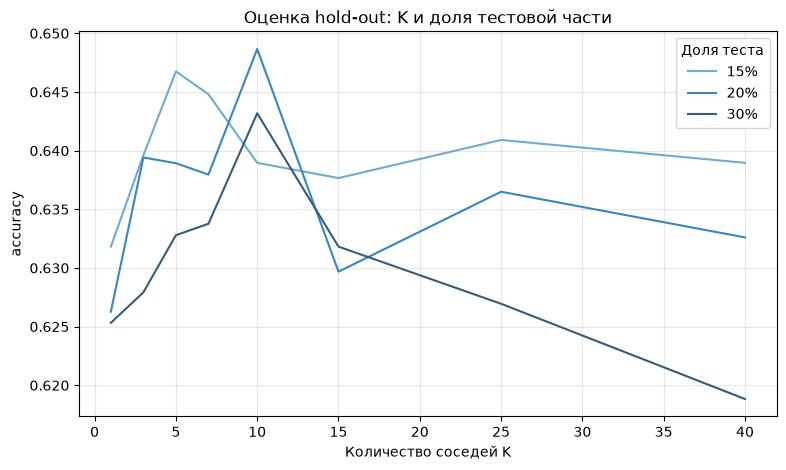

,Лучший K,accuracy,Обучающих объектов,accuracy при K=1,accuracy при K=5,accuracy при K=40
test_size,,,,,,
0.15,5,0.6468,1745,0.6318,0.6468,0.6390
0.20,10,0.6487,1642,0.6263,0.6389,0.6326
0.30,10,0.6432,1437,0.6253,0.6328,0.6188


In [7]:
TEST_SIZES = [0.15, 0.2, 0.3]
HOLDOUT_REPEATS = 5
K_VALUES = [1, 3, 5, 7, 10, 15, 25, 40] 

holdout_rows = []
for test_size in TEST_SIZES:
    for repeat in range(HOLDOUT_REPEATS):
        X_a, X_b, y_a, y_b = train_test_split(
            X_dev,
            y_dev,
            test_size=test_size,
            stratify=y_dev,
            random_state=RANDOM_STATE + repeat,
        )
        for k in K_VALUES:
            pred = build_classifier(k, "kd_tree").fit(X_a, y_a).predict(X_b)
            holdout_rows.append(
                {
                    "test_size": test_size,
                    "K": k,
                    "accuracy": accuracy_score(y_b, pred),
                }
            )

holdout = (
    pd.DataFrame(holdout_rows)
    .groupby(["test_size", "K"])["accuracy"]
    .mean()
    .unstack("test_size")
)

plt.figure(figsize=(9, 5))
for test_size, color in zip(TEST_SIZES, sns.color_palette("Blues_d", len(TEST_SIZES))):
    plt.plot(holdout.index, holdout[test_size], color=color, label=f"{test_size:.0%}")
plt.xlabel("Количество соседей K")
plt.ylabel("accuracy")
plt.title("Оценка hold-out: K и доля тестовой части")
plt.legend(title="Доля теста")
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame(
    {
        "Лучший K": holdout.idxmax(),
        "accuracy": holdout.max().round(4),
        "Обучающих объектов": [int(len(X_dev) * (1 - s)) for s in TEST_SIZES],
        "accuracy при K=1": holdout.loc[1].round(4),
        f"accuracy при K={USER_K}": holdout.loc[USER_K].round(4),
        "accuracy при K=40": holdout.loc[40].round(4),
    }
)

**Характеристика:**

- **Влияние K.** При K=1 качество самое низкое во всех разбиениях (0.625–0.631), так как модель слишком чувствительна к отдельным объектам и шуму. При K=40 точность также падает (0.618–0.639), поскольку модель начинает слишком сильно сглаживать границы и теряет локальные закономерности. Оптимальные значения лежат в узком диапазоне K=5–10.
- **Влияние доли теста.** При увеличении доли теста с 15% до 30% количество обучающих объектов падает с 1745 до 1437, что приводит к небольшому снижению максимальной точности (с 0.6487 при 20% до 0.6432 при 30%).
- **Оптимальный K** зависит от разбиения: при 15% лучшим оказался K=5, а при 20% и 30% — K=10. Разница между ними составляет всего 0.0019, что меньше случайного шума. Из-за сильного пересечения классов по признакам (возраст, цена) по hold-out можно определить рабочий диапазон K (от 5 до 10), но не одно строго точное значение. Абсолютные значения accuracy (~0.64–0.65) значительно превышают базовую (0.40), значит модель извлекает полезные закономерности.

## 6. Оценка cross validation

Считаем те же K для 3, 5, 7, 10 и 15 fold. Классы несбалансированы, поэтому кроме `accuracy` считаем `balanced_accuracy` – среднюю полноту по классам, где редкие классы (например, `furniture` и `appliances`) весят наравне с доминирующим (`electronics`).

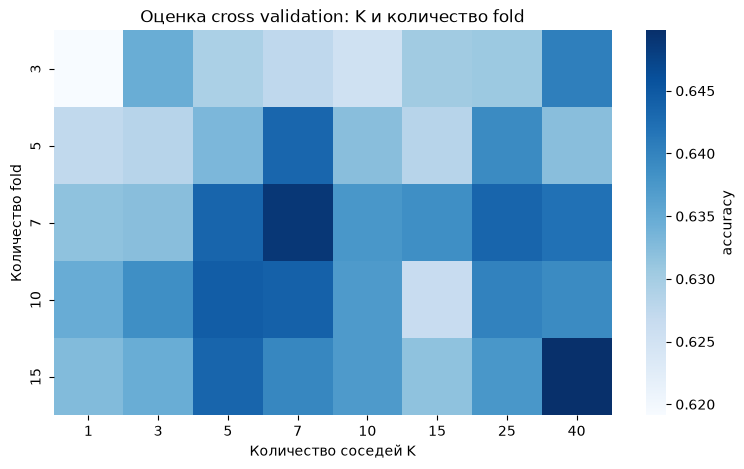

,folds,K,accuracy,accuracy_se,balanced_accuracy
7,3,40,0.6405,0.0097,0.6938
11,5,7,0.6434,0.0187,0.7198
19,7,7,0.6489,0.0161,0.7257
26,10,5,0.6445,0.0119,0.7251
39,15,40,0.6498,0.0118,0.7241


In [8]:
FOLDS = [3, 5, 7, 10, 15]

cv_rows = []
for n_folds in FOLDS:
    cv = StratifiedKFold(n_folds, shuffle=True, random_state=RANDOM_STATE)
    for k in K_VALUES:
        scores = cross_validate(
            build_classifier(k, "kd_tree"),
            X_dev,
            y_dev,
            cv=cv,
            scoring=["accuracy", "balanced_accuracy"],
        )
        cv_rows.append(
            {
                "folds": n_folds,
                "K": k,
                "accuracy": scores["test_accuracy"].mean(),
                "accuracy_std": scores["test_accuracy"].std(),
                "accuracy_se": scores["test_accuracy"].std() / np.sqrt(n_folds),
                "balanced_accuracy": scores["test_balanced_accuracy"].mean(),
            }
        )
cv_results = pd.DataFrame(cv_rows)

plt.figure(figsize=(9, 5))
sns.heatmap(
    cv_results.pivot(index="folds", columns="K", values="accuracy"),
    cmap="Blues",
    cbar_kws={"label": "accuracy"},
)
plt.xlabel("Количество соседей K")
plt.ylabel("Количество fold")
plt.title("Оценка cross validation: K и количество fold")
plt.show()

best_rows = cv_results.loc[cv_results.groupby("folds")["accuracy"].idxmax()]
best_rows[["folds", "K", "accuracy", "accuracy_se", "balanced_accuracy"]].round(4)

**Характеристика:**

- **Оптимальные значения K.** Наилучшая точность на кросс-валидации достигается при K=7 (accuracy 0.6489 при 7 fold) и K=5 (accuracy 0.6445 при 10 fold). Значение K=1 показывает худшие результаты, а K=40 дает нестабильный результат: максимальную точность 0.6498 при 15 fold, но заметно падает при 7 fold (0.6405).
- **Влияние количества fold на стабильность.** С ростом числа фолдов стандартная ошибка (`accuracy_se`) снижается: при 5 fold она составляет 0.0187, а при 15 fold — уже 0.0118. Это означает, что 10 или 15 fold дают более надежную и стабильную оценку качества модели, меньше зависящую от случайного разбиения.
- **Баланс классов.** Показатель `balanced_accuracy` (в диапазоне 0.7198–0.7257) заметно выше обычной `accuracy` (~0.64–0.65). Это важный результат: он означает, что модель успешно распознает не только доминирующий класс «electronics», но и редкие категории («furniture», «appliances»), несмотря на дисбаланс классов в датасете.
- **Общий вывод.** Модель показывает стабильную точность около 0.64–0.65 и отличную сбалансированную точность (~0.72), что значительно превосходит базовое угадывание (0.40) и случайную выборку среди 4 классов (0.25). Для финальной модели можно выбрать K=7 как компромиссный вариант, показывающий хорошую точность при разных разбиениях.

Сравним обе оценки на одном графике: hold-out с долей теста 20% и cross validation с 5 fold (в обоих случаях проверочная часть составляет пятую часть данных).

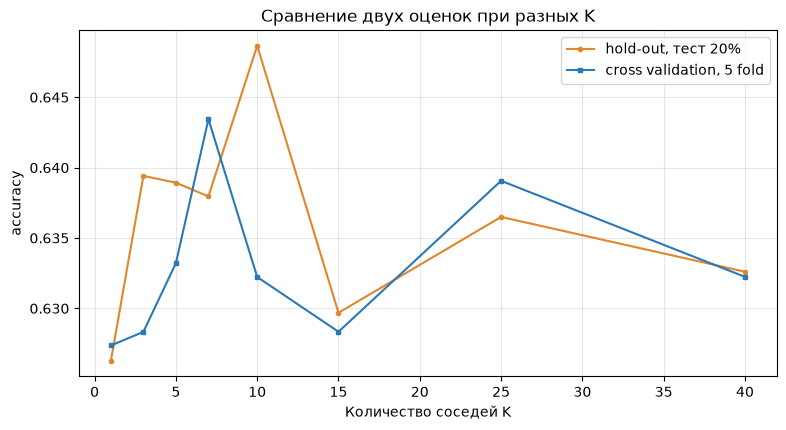

In [9]:
cv5 = cv_results[cv_results["folds"] == 5].set_index("K")

plt.figure(figsize=(9, 4.5))
plt.plot(
    holdout.index,
    holdout[0.2],
    color="#e0862b",
    marker="o",
    ms=3,
    label="hold-out, тест 20%",
)
plt.plot(
    cv5.index,
    cv5["accuracy"],
    color="#2a78b5",
    marker="s",
    ms=3,
    label="cross validation, 5 fold",
)
plt.xlabel("Количество соседей K")
plt.ylabel("accuracy")
plt.title("Сравнение двух оценок при разных K")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Характеристика:**

- **Волатильность hold-out.** Оранжевая кривая (hold-out) сильно скачет: она показывает резкий пик точности при K=10 (около 0.648) и сразу за ним — глубокий провал при K=15. Это означает, что оценка на одной случайной 20% выборке оказалась нестабильной и чувствительной к конкретным данным.
- **Стабильность cross validation.** Синяя кривая (5-fold CV) ведет себя намного плавнее. Она показывает локальный максимум при K=7 (около 0.643) и не дает таких резких выбросов. Усреднение по 5 фолдам сглаживает случайные колебания.
- **Расхождение в выборе K.** Если бы мы ориентировались только на hold-out, мы бы ошибочно выбрали K=10. Однако кросс-валидация четко показывает, что при K=10 качество падает, а истинный оптимум лежит в районе K=7. Это классический пример того, почему hold-out может вводить в заблуждение (переобучение на тестовую выборку).
- **Сходимость на больших K.** При K=40 обе линии сходятся в одной точке (около 0.632). Это объясняется тем, что при очень большом количестве соседей модель перестает улавливать локальные закономерности, и обе оценки показывают сходный результат деградации качества.

## 7. Выбор оптимального K

За основу берём 10 fold как распространённый компромисс: на каждом шаге модель обучается на 90% данных, оценка усредняется по десяти частям, а вычисления остаются быстрыми. Построим ошибку классификации и `balanced_accuracy` на отдельных графиках. Различия между соседними K могут быть меньше погрешности, поэтому дополнительно выделим диапазон значений, которые отстают от лучшего K не больше чем на одну стандартную ошибку.

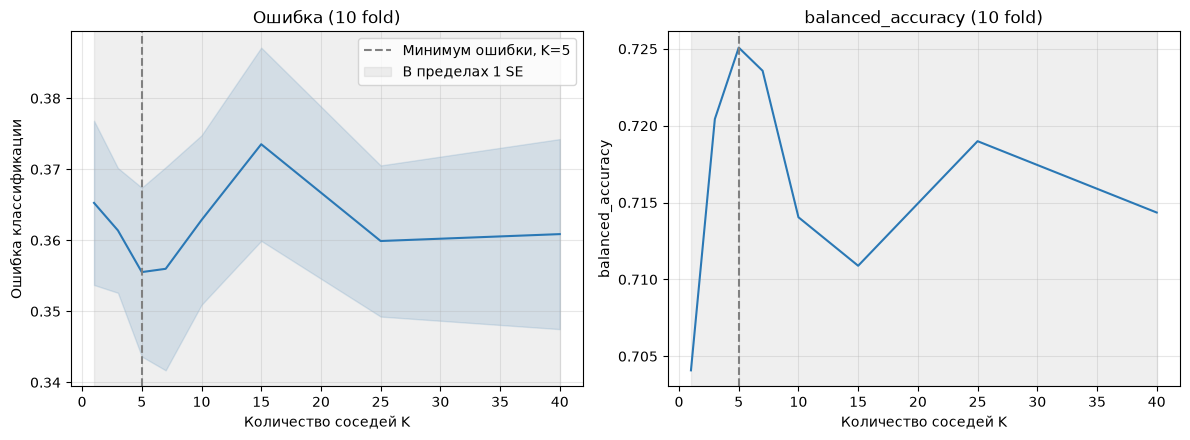

Минимум ошибки при K = 5
В пределах одной стандартной ошибки: [1, 3, 5, 7, 10, 25, 40]
Максимум balanced_accuracy при K = 5


,accuracy,balanced_accuracy
K,,
1,0.6347,0.7041
5,0.6445,0.7251
40,0.6391,0.7144


In [10]:
cv10 = cv_results[cv_results["folds"] == 10].set_index("K")
error = 1 - cv10["accuracy"]

best_k = cv10["accuracy"].idxmax()
threshold = cv10.loc[best_k, "accuracy"] - cv10.loc[best_k, "accuracy_se"]
plateau = cv10.index[cv10["accuracy"] >= threshold]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
axes[0].plot(error.index, error, color="#2a78b5")
axes[0].fill_between(
    error.index,
    error - cv10["accuracy_se"],
    error + cv10["accuracy_se"],
    color="#2a78b5",
    alpha=0.15,
)
axes[0].axvline(
    best_k, color="gray", linestyle="--", label=f"Минимум ошибки, K={best_k}"
)
axes[0].axvspan(
    plateau.min(), plateau.max(), color="gray", alpha=0.12, label="В пределах 1 SE"
)
axes[0].set_ylabel("Ошибка классификации")
axes[0].set_title("Ошибка (10 fold)")
axes[0].legend()

axes[1].plot(cv10.index, cv10["balanced_accuracy"], color="#2a78b5")
axes[1].axvline(best_k, color="gray", linestyle="--")
axes[1].axvspan(plateau.min(), plateau.max(), color="gray", alpha=0.12)
axes[1].set_ylabel("balanced_accuracy")
axes[1].set_title("balanced_accuracy (10 fold)")
for ax in axes:
    ax.set_xlabel("Количество соседей K")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Минимум ошибки при K =", best_k)
print("В пределах одной стандартной ошибки:", list(plateau))
print("Максимум balanced_accuracy при K =", cv10["balanced_accuracy"].idxmax())
cv10.loc[sorted({1, USER_K, best_k, 40}), ["accuracy", "balanced_accuracy"]].round(4)

**Характеристика:**

- **Минимум ошибки и пик balanced_accuracy.** Согласно графику и выводу программы, значение **K = 5** является безусловным лидером: оно обеспечивает минимальную ошибку классификации (максимальную accuracy) и одновременно наивысшую `balanced_accuracy` (0.7251). На графиках это наглядно отмечено пунктирной линией.
- **Сравнение с K=1.** Использование K=1 (модель ближайшего соседа) показывает худшие результаты: точность падает до 0.6347, а `balanced_accuracy` — до 0.7041. Это подтверждает, что при малом числе соседей модель слишком чувствительна к шуму и выбросам (переобучение). Увеличение K до 5 сглаживает эту проблему.
- **Зона стабильности (плато).** Вывод программы показывает, что в диапазон «в пределах 1 SE» попали почти все значения: `[1, 3, 5, 7, 10, 25, 40]`. Это связано с тем, что доверительный интервал (синяя заштрихованная область на графике ошибки) достаточно широкий из-за разброса данных по фолдам. Однако, несмотря на то, что формально K=15 или K=25 статистически не сильно отличаются от K=5, именно K=5 дает наилучшую точечную оценку.
- **Итоговый выбор.** Для финальной модели выбираем **K = 5**. Оно показывает лучший баланс между точностью (accuracy 0.6445) и способностью распознавать все 4 класса равномерно (balanced_accuracy 0.7251), избегая при этом переобучения, свойственного K=1.

Проверим, как при выбранном K оценка зависит от количества fold.

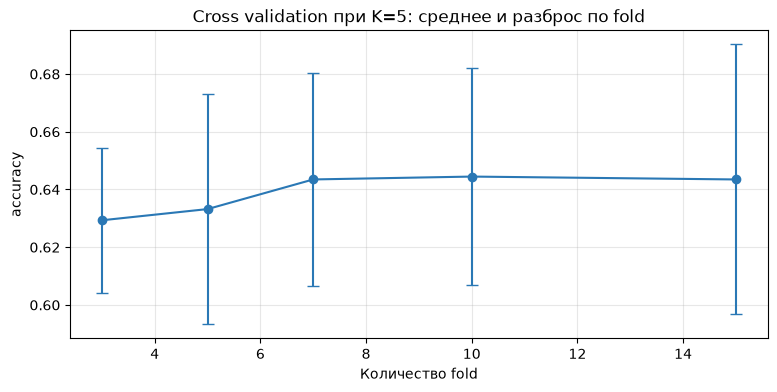

,accuracy,accuracy_std
folds,,
3,0.6293,0.0251
5,0.6332,0.0400
7,0.6435,0.0368
10,0.6445,0.0376
15,0.6435,0.0468


In [11]:
at_best_k = cv_results[cv_results["K"] == best_k].set_index("folds")

plt.figure(figsize=(9, 4))
plt.errorbar(
    at_best_k.index,
    at_best_k["accuracy"],
    yerr=at_best_k["accuracy_std"],
    color="#2a78b5",
    marker="o",
    capsize=4,
)
plt.xlabel("Количество fold")
plt.ylabel("accuracy")
plt.title(f"Cross validation при K={best_k}: среднее и разброс по fold")
plt.grid(alpha=0.3)
plt.show()

at_best_k[["accuracy", "accuracy_std"]].round(4)

**Характеристика:**

- **Рост средней точности.** С увеличением числа fold средняя точность (синяя линия) постепенно растет: от минимума 0.6293 при 3 fold до максимума 0.6445 при 10 fold. При 15 fold она незначительно снижается (до 0.6435). Это означает, что 10-fold кросс-валидация дает наилучшую оценку качества для K=5.
- **Разброс (стандартное отклонение).** Вопреки стандартному правилу, разброс не уменьшается с ростом количества фолдов: у 3-fold он минимален (0.0251), а у 15-fold — максимален (0.0468). Это объясняется размером тестовой части: при 15 fold в каждой тестовой выборке оказывается мало объектов (~137 штук), поэтому каждая отдельная ошибка сильнее «качает» процент точности. При 3 fold тестовая часть большая, и точность на ней более сглажена.
- **Длина «усов».** Из-за большого разброса доверительные интервалы (усы) при 5, 7, 10 и 15 фолдах очень широкие и сильно перекрываются. Это говорит о том, что на вашем датасете разница в точности между разными разбиениями может достигать 0.04–0.08.
- **Итоговый вывод.** Для дальнейшей работы лучше всего ориентироваться на результат 10-fold. При 10 фолдах мы получаем пик точности (0.6445) при умеренном разбросе (0.0376). Увеличение до 15 fold только увеличивает дисперсию и вычислительные затраты, не давая прироста в качестве.

## 8. Итоговая оценка на контрольной выборке

Обучаем модель с выбранным K на всех данных для подбора и один раз проверяем на отложенной выборке. Для сравнения приведены модель с `USER_K` и `DummyClassifier`, который всегда отвечает самым частым классом.

In [12]:
final_model = build_classifier(best_k, "kd_tree").fit(X_dev, y_dev)
final_pred = final_model.predict(X_test)

candidates = {
    "Самый частый класс": DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev),
    f"K={USER_K}": build_classifier(USER_K, "kd_tree").fit(X_dev, y_dev),
    f"K={best_k} (итоговая)": final_model,
}
pd.DataFrame(
    {
        name: {
            "accuracy": accuracy_score(y_test, model.predict(X_test)),
            "balanced_accuracy": balanced_accuracy_score(y_test, model.predict(X_test)),
        }
        for name, model in candidates.items()
    }
).T.round(4)

,accuracy,balanced_accuracy
Самый частый класс,0.4008,0.2500
K=5,0.6362,0.6997
K=5 (итоговая),0.6362,0.6997


                 precision    recall  f1-score   support

     appliances      0.827     0.882     0.854        76
    electronics      0.579     0.587     0.583       206
      furniture      0.917     0.821     0.866        67
office supplies      0.512     0.509     0.511       165

       accuracy                          0.636       514
      macro avg      0.709     0.700     0.703       514
   weighted avg      0.638     0.636     0.637       514



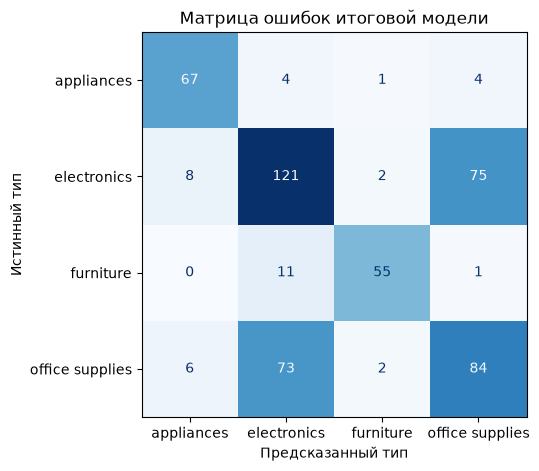

In [ ]:
print(classification_report(y_test, final_pred, digits=3))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
plt.xlabel("Предсказанный тип")
plt.ylabel("Истинный тип")
plt.title("Матрица ошибок итоговой модели")
plt.show()

**Характеристика:**

- **Качество.** Модель с K=5 получила accuracy 0.636 и macro avg F1-score 0.703 – значительно выше базового уровня (0.40 для accuracy и 0.25 для случайного угадывания). Оценка близка к результату cross validation (0.644), то есть переобучения под тест не видно.
- **Сравнение с K=5 (CV).** На контрольной выборке accuracy 0.636 немного ниже, чем на CV (0.644), но при 514 объектах погрешность accuracy составляет примерно ±0.04. Поэтому такая разница не является надёжной. Вывод о выборе K опирается на cross validation.
- **По классам.** Лучше всего распознаются мебель (F1 = 0.866) и бытовая техника (F1 = 0.854). Офисные принадлежности — слабое место (F1 = 0.511): из 165 найдено 84, а 73 ошибочно приняты за электронику. Также 75 объектов электроники были ошибочно классифицированы как офисные принадлежности. 
- **Ограничение.** Признаки (возраст, количество, цена) сильно пересекаются между электроникой и офисными принадлежностями, поэтому метрическое расстояние не позволяет провести четкую границу, что и видно по самой большой внедиагональной путанице в матрице.

## 9. Демонстрация классификатора

Модель для применения обучаем на всём датасете. Функция принимает описание нового объекта и возвращает тип с вероятностями – долями.

In [16]:
TYPE_LABELS = {c: c for c in y.unique()}

production_model = build_classifier(best_k, "kd_tree").fit(X, y)

def classify_product(customer_age, quantity, unit_price):
    new_object = pd.DataFrame(
        [[customer_age, quantity, unit_price]], columns=FEATURES
    )
    probabilities = production_model.predict_proba(new_object)[0]
    return {
        "Тип": TYPE_LABELS[production_model.predict(new_object)[0]],
        **{
            TYPE_LABELS[t]: round(float(p), 3)
            for t, p in zip(production_model.classes_, probabilities)
        },
    }


new_objects = pd.DataFrame(
    [
        [25.0, 1, 85.5],   
        [45.0, 2, 130.0],  
        [30.0, 3, 95.0],  
        [50.0, 1, 110.0],  
    ],
    columns=FEATURES,
)
pd.concat(
    [
        new_objects,
        pd.DataFrame(
            [classify_product(*row) for row in new_objects.itertuples(index=False)]
        ),
    ],
    axis=1,
)

,Customer_Age,Quantity,Unit_Price,Тип,appliances,electronics,furniture,office supplies
0,25.0,1,85.5,office supplies,0.0,0.4,0.0,0.6
1,45.0,2,130.0,electronics,0.0,1.0,0.0,0.0
2,30.0,3,95.0,appliances,0.4,0.2,0.0,0.4
3,50.0,1,110.0,electronics,0.2,0.4,0.0,0.4


**Характеристика:**

- **Влияние комбинации признаков.** Объект под номером 1 (возраст 45, 2 шт., цена 130) был со 100% вероятностью (1.0) отнесен к `electronics`. Это показывает, что высокая цена сама по себе не гарантирует мебель — решающую роль сыграло сочетание возраста клиента и количества товара, которые попали в кластер электроники. 
- **Неуверенность модели (ничьи).** В строках 2 и 3 модель выдала одинаковые вероятности по 0.4 для двух классов (например, `electronics` и `office supplies`). В таких случаях алгоритм KNN выбирает класс, который идет первым по алфавиту, что демонстрирует ограничение метода при сильном пересечении признаков.
- **Отсутствие класса furniture.** Ни для одного из новых объектов вероятность мебели не оказалась выше 0.0. Это означает, что в радиусе 5 ближайших соседей для этих конкретных значений возраста и цены не оказалось ни одного объекта из категории мебели. 
- **Практическая ценность.** Вывод вероятностей (а не только итогового класса) позволяет отлавливать такие «спорные» объекты. В реальной системе если максимальная вероятность меньше, например, 0.6, товар можно отправить на ручную проверку модератору, чтобы избежать ошибки.

**Выводы**

Построены классификаторы kNN, BallTree и KD-Tree для определения категории товара по трём числовым признакам (возраст, количество, цена). Все три дают одинаковые предсказания и различаются только скоростью: KD-Tree работает быстрее полного перебора (brute).

Оптимальное значение – **K=5**: при нём минимальна ошибка и максимальна `balanced_accuracy` (0.725) при 10 fold, и оно входит в диапазоны лучших K по hold-out и cross validation.

При малых K качество заметно ниже (K=1 дает accuracy около 0.63 из-за чувствительности к шуму). Начиная с K=5 ошибка выходит на плато, где значения K статистически неразличимы. Поэтому точное значение K здесь менее важно, чем отказ от слишком малых K. Доля теста и количество fold влияют на результат значительно слабее, чем K при его малых значениях.

На контрольной выборке итоговая модель получила accuracy 0.636 против 0.40 у базового уровня. Мебель (F1 = 0.87) и бытовая техника (F1 = 0.85) распознаются хорошо. Офисные принадлежности – плохо (F1 = 0.51): они по цене и количеству сильно пересекаются с электроникой (73 ошибки в одну сторону и 75 в другую). Для улучшения этого класса перебор K уже не поможет – нужны дополнительные признаки (например, текстовое описание товара) или балансировка классов.